# Sequential E2T2 on the peg-slide: experiments

The method is `Sequential_E2T2_peg_slide_2D.ipynb`, loaded once below; editing it during a run does not affect the run.

**Claim.** On the peg-slide, with a peg that can jam and the block displaced beyond the slot's clearance, the sliding target with forgetting reaches the goal more often than E2T2. The taught world and offsets within the clearance are reported as well.

**Measures.** The headline is the **success share**: trials that reach the goal within `MAX_STEPS`. Every failure is a **slip-out** (inserted, the barrier removed, but no goal) or **never inserted** (the barrier still stands). The shares of time in the dead end, jammed, and retrying (the back edge a stage or more behind) are reported beside them. A sequence's trials share an offset, so the standard errors are taken over sequences.

**Experiments.**
1. Ablation: E2T2, its static target with forgetting, and the sliding target with forgetting, without and with the retry.
2. Forgetting horizon: $T_{\mathrm{f}}$ at half and twice its derived value, and no forgetting, with the sliding target and no retry.
3. Offset sweep: E2T2 against the sliding target with forgetting, without and with the retry, from the taught world to $\pm 0.11$, through offsets within the clearance.

Each experiment writes its results to `final/output/` as soon as it ends.

In [1]:
%%capture method
%run -i Sequential_E2T2_peg_slide_2D.ipynb

In [2]:
import time
from multiprocessing import Pool
from pathlib import Path
from types import SimpleNamespace

import numpy as np
from IPython import get_ipython
from matplotlib import pyplot as plt

m = SimpleNamespace(**get_ipython().user_ns)  # the method notebook's names

N_TRIALS, N_SEQ, N_SEQ_SWEEP = 5, 6, 3  # quick run; the long run is 10, 20, 10
WORKERS = 16  # of 24 cores, so other work on the machine stays responsive
OUT = Path("../../output")
OUT.mkdir(exist_ok=True)
draw = np.random.default_rng(3)
# The displaced sequences of the ablation; a quick run uses the first N_SEQ.
DISPLACED = draw.choice([-1.0, 1.0], 20) * draw.uniform(0.08, 0.11, 20)


# (N_TRIALS, 7): steps, success, inserted, dead-end entries, dead-end, jammed and retrying time shares
def summarise(sliding, lam, retry, offset, seq):
    return np.array(
        [
            [
                r["steps"],
                r["success"],
                r["inserted"],
                r["dead_ends"],
                r["dead_share"],
                r["jam_share"],
                r["retry_share"],
            ]
            for r in m.run_sequence(sliding, lam, retry, offset, seq, N_TRIALS)
        ],
        float,
    )


# settings: name -> (sliding, lambda, retry); one sequence per offset
def experiment(name, settings, offsets):
    t0 = time.time()
    jobs = [(*s, off, seq) for s in settings.values() for seq, off in enumerate(offsets)]
    with Pool(WORKERS) as pool:
        out = pool.starmap(summarise, jobs)
    n = len(offsets)
    res = {k: np.array(out[i * n : (i + 1) * n]) for i, k in enumerate(settings)}
    np.savez(OUT / f"{name}_{N_TRIALS}trials_{n}seq.npz", offsets=offsets, **res)
    print(f"{name}: {len(jobs)} sequences in {(time.time() - t0) / 60:.1f} min")
    return res


# (n_seq, n_trials, 7) -> per sequence: success, slip-out, never inserted, dead-end, jammed and retrying time
def shares(R):
    success, inserted = R[:, :, 1], R[:, :, 2]
    return np.stack(
        [
            success.mean(1),
            (inserted * (1 - success)).mean(1),
            (1 - inserted).mean(1),
            R[:, :, 4].mean(1),
            R[:, :, 5].mean(1),
            R[:, :, 6].mean(1),
        ],
        axis=1,
    )


def table(res, offsets):
    for side, sel in (("all", np.full(len(offsets), True)), ("+", offsets > 0), ("-", offsets < 0)):
        if not sel.any():
            continue
        print(f"offsets {side} ({sel.sum()} sequences)")
        for k, R in res.items():
            s = shares(R[sel])
            se = s.std(0, ddof=1) / np.sqrt(len(s)) if len(s) > 1 else np.full(6, np.nan)
            print(
                f"  {k:28s} success {s[:, 0].mean():.2f} +- {se[0]:.2f}, slip-out {s[:, 1].mean():.2f}, "
                f"never inserted {s[:, 2].mean():.2f}, dead-end time {s[:, 3].mean():.2f}, jammed {s[:, 4].mean():.2f}, retrying {s[:, 5].mean():.2f}"
            )

### 1. Ablation
Whether forgetting alone does the work, or only with the target that slides with the phase, and what the retry adds. The four settings on the same displaced sequences and noise.

In [3]:
ABLATION = {
    "E2T2": (False, 1.0, False),
    "static + forgetting": (False, m.lam_f, False),
    "sliding + forgetting": (True, m.lam_f, False),
    "sliding + forgetting + retry": (True, m.lam_f, True),
}
offsets_d = DISPLACED[:N_SEQ]
abl = experiment("ablation", ABLATION, offsets_d)
table(abl, offsets_d)

ablation: 24 sequences in 4.6 min
offsets all (6 sequences)
  E2T2                         success 0.10 +- 0.07, slip-out 0.23, never inserted 0.67, dead-end time 0.65, jammed 0.04, retrying 0.00
  static + forgetting          success 0.10 +- 0.04, slip-out 0.80, never inserted 0.10, dead-end time 0.39, jammed 0.04, retrying 0.00
  sliding + forgetting         success 0.90 +- 0.10, slip-out 0.00, never inserted 0.10, dead-end time 0.46, jammed 0.08, retrying 0.00
  sliding + forgetting + retry success 0.83 +- 0.13, slip-out 0.03, never inserted 0.13, dead-end time 0.46, jammed 0.07, retrying 0.16
offsets + (2 sequences)
  E2T2                         success 0.20 +- 0.20, slip-out 0.30, never inserted 0.50, dead-end time 0.60, jammed 0.06, retrying 0.00
  static + forgetting          success 0.00 +- 0.00, slip-out 1.00, never inserted 0.00, dead-end time 0.19, jammed 0.04, retrying 0.00
  sliding + forgetting         success 0.70 +- 0.30, slip-out 0.00, never inserted 0.30, dead-end ti

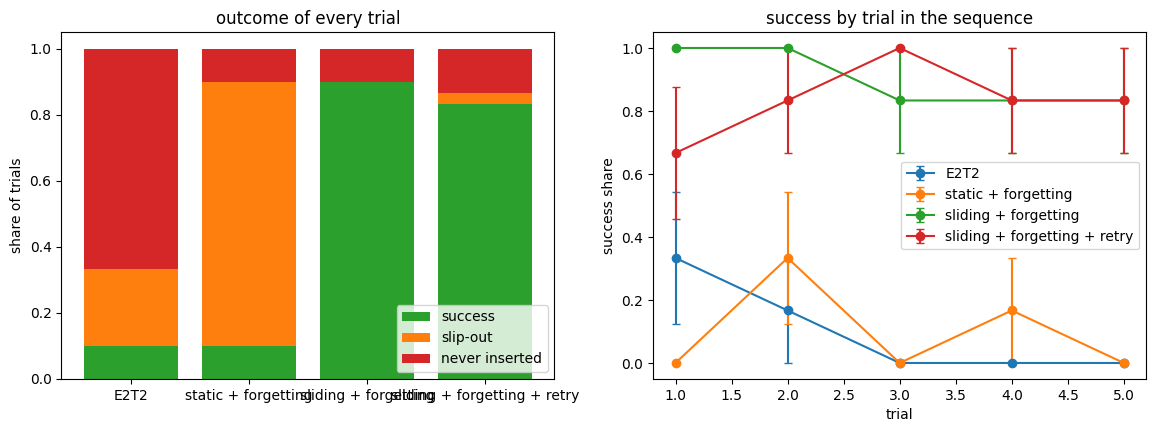

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
names = list(abl)
s = np.array([shares(abl[k]).mean(0) for k in names])
bottom = np.zeros(len(names))
for j, (lbl, col) in enumerate(
    (("success", "tab:green"), ("slip-out", "tab:orange"), ("never inserted", "tab:red"))
):
    ax[0].bar(names, s[:, j], bottom=bottom, color=col, label=lbl)
    bottom += s[:, j]
ax[0].set(ylabel="share of trials", title="outcome of every trial")
ax[0].legend()
for k in names:
    R = abl[k][:, :, 1]
    ax[1].errorbar(
        range(1, N_TRIALS + 1),
        R.mean(0),
        R.std(0, ddof=1) / np.sqrt(len(R)),
        marker="o",
        capsize=3,
        label=k,
    )
ax[1].set(
    xlabel="trial",
    ylabel="success share",
    ylim=(-0.05, 1.05),
    title="success by trial in the sequence",
)
ax[1].legend()
plt.show()

### 2. Forgetting horizon
$T_{\mathrm{f}}$ is derived, the half-life equal to the master's duration. Half and twice it, around the ablation's $\times 1$, and no forgetting ($\times \infty$), with the sliding target and no retry.

forgetting_horizon: 18 sequences in 4.6 min
offsets all (6 sequences)
  T_f x0.5                     success 0.73 +- 0.16, slip-out 0.00, never inserted 0.27, dead-end time 0.45, jammed 0.08, retrying 0.00
  T_f x1                       success 0.90 +- 0.10, slip-out 0.00, never inserted 0.10, dead-end time 0.46, jammed 0.08, retrying 0.00
  T_f x2                       success 0.73 +- 0.12, slip-out 0.03, never inserted 0.23, dead-end time 0.54, jammed 0.06, retrying 0.00
  no forgetting                success 0.23 +- 0.08, slip-out 0.03, never inserted 0.73, dead-end time 0.71, jammed 0.03, retrying 0.00
offsets + (2 sequences)
  T_f x0.5                     success 0.50 +- 0.50, slip-out 0.00, never inserted 0.50, dead-end time 0.67, jammed 0.04, retrying 0.00
  T_f x1                       success 0.70 +- 0.30, slip-out 0.00, never inserted 0.30, dead-end time 0.67, jammed 0.03, retrying 0.00
  T_f x2                       success 0.50 +- 0.30, slip-out 0.00, never inserted 0.50, d

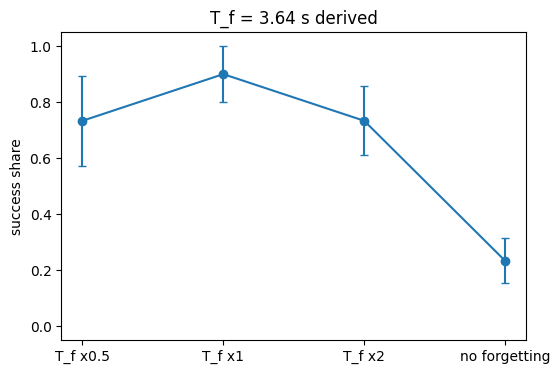

In [5]:
TF = {f"T_f x{f}": (True, np.exp(-m.DT / (f * m.T_F)), False) for f in (0.5, 2)} | {
    "no forgetting": (True, 1.0, False)
}
tf = experiment("forgetting_horizon", TF, offsets_d)
tf = {
    "T_f x0.5": tf["T_f x0.5"],
    "T_f x1": abl["sliding + forgetting"],
    "T_f x2": tf["T_f x2"],
    "no forgetting": tf["no forgetting"],
}
table(tf, offsets_d)

fig, a = plt.subplots(figsize=(6, 4))
s = [shares(R)[:, 0] for R in tf.values()]
a.errorbar(
    list(tf),
    [v.mean() for v in s],
    [v.std(ddof=1) / np.sqrt(len(v)) for v in s],
    marker="o",
    capsize=3,
)
a.set(ylabel="success share", ylim=(-0.05, 1.05), title=f"T_f = {m.T_F:.2f} s derived")
plt.show()

### 3. Offset sweep
From the taught world, through offsets within the clearance ($\pm$ half of it), to beyond it. Each offset has its own sequences.

offset_sweep: 81 sequences in 14.6 min


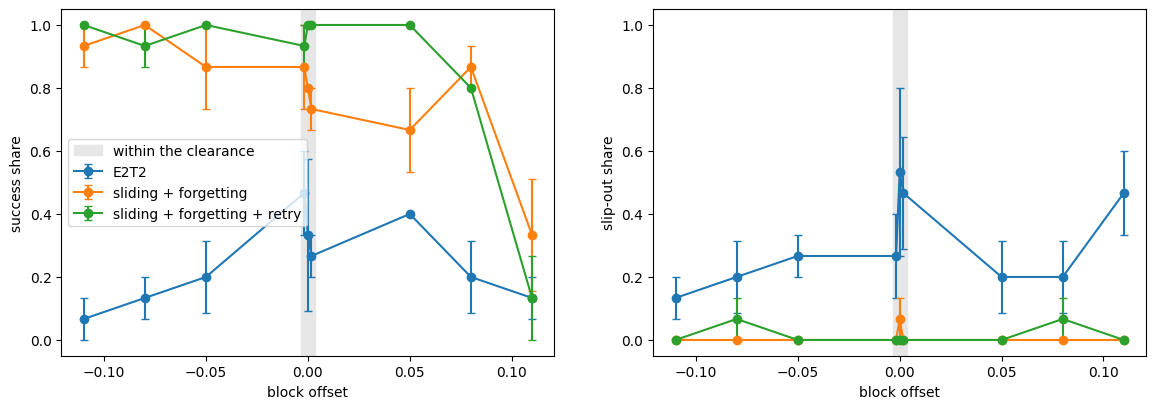

offset -0.1100: E2T2 0.07, sliding + forgetting 0.93, sliding + forgetting + retry 1.00
offset -0.0800: E2T2 0.13, sliding + forgetting 1.00, sliding + forgetting + retry 0.93
offset -0.0500: E2T2 0.20, sliding + forgetting 0.87, sliding + forgetting + retry 1.00
offset -0.0018: E2T2 0.47, sliding + forgetting 0.87, sliding + forgetting + retry 0.93
offset +0.0000: E2T2 0.33, sliding + forgetting 0.80, sliding + forgetting + retry 1.00
offset +0.0018: E2T2 0.27, sliding + forgetting 0.73, sliding + forgetting + retry 1.00
offset +0.0500: E2T2 0.40, sliding + forgetting 0.67, sliding + forgetting + retry 1.00
offset +0.0800: E2T2 0.20, sliding + forgetting 0.87, sliding + forgetting + retry 0.80
offset +0.1100: E2T2 0.13, sliding + forgetting 0.33, sliding + forgetting + retry 0.13


In [6]:
GRID = np.array([-0.11, -0.08, -0.05, -m.CLEAR / 2, 0.0, m.CLEAR / 2, 0.05, 0.08, 0.11])
offsets_s = np.repeat(GRID, N_SEQ_SWEEP)
sweep = experiment("offset_sweep", m.METHODS, offsets_s)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for k, R in sweep.items():
    s = shares(R)
    for a, j in zip(ax, (0, 1), strict=True):
        per = np.array([s[offsets_s == o, j] for o in GRID])
        se = per.std(1, ddof=1) / np.sqrt(N_SEQ_SWEEP) if N_SEQ_SWEEP > 1 else None
        a.errorbar(GRID, per.mean(1), se, marker="o", capsize=3, label=k)
for a, lbl in zip(ax, ("success share", "slip-out share"), strict=True):
    a.axvspan(-m.CLEAR, m.CLEAR, color="0.9", label="within the clearance")
    a.set(xlabel="block offset", ylabel=lbl, ylim=(-0.05, 1.05))
ax[0].legend()
plt.show()

for o in GRID:
    sel = offsets_s == o
    print(
        f"offset {o:+.4f}: "
        + ", ".join(f"{k} {shares(R[sel])[:, 0].mean():.2f}" for k, R in sweep.items())
    )